#### Задача 1.

Пользователь вводит путь к файлу, а ваша программа должна 1) проверить, что путь введен правильно и такой файл существует, 2) попытаться открыть этот файл, 3) считать из него текст и вывести на экран первые 200 символов, если текст длиннее 200 символов, и весь текст, если не длиннее.

In [2]:
import os
user_path = input('Введите путь к файлу')
existence = os.path.exists(user_path)
while not existence:
    print('Ошибка. Введите путь заново')
    user_path = input('Введите путь к файлу')
    existence = os.path.exists(user_path)
with open(user_path, 'r', encoding='utf8') as file:
    sum = 0
    text = ''
    for line in file:
        sum += len(line)
        if sum < 200:
            text += line
        elif sum - len(line) < 200:
            text += line[:200 - sum]
        else:
            break
print(text)

Если каких-то зверей Сидни не любил сильнее остальных, то это были кошки. Нельзя сказать, что он вообще не любил животных, — он очень любил старого ретривера, бывшего у него когда-то. Но кошки будто п


#### Задача 2.

Напишите программу - телефонный справочник.

В программе должно быть:

1. Функция для поиска номера по справочнику
2. Функция для создания новой записи
3. Функция для сохранения справочника в файл
4. В начале программы нужно проверять, существует ли файл со справочником
5. В цикле нужно предлагать человеку варианты действий.

In [6]:
import pickle
import os.path

def download():
    with open('sem07/02telephone_book.pkl', 'rb') as tel_book:
        data = pickle.load(tel_book)
        print(data) #для проверки
    return data

def search_per():
    # скачиваем словарь, инпут, через гет! чтобы не вывалилась ошибка
    data = download()
    person = input('Введите имя контакта')
    res = []
    for per in data.keys():
        if person in per:
            res.append(per)
    if not res:
        print('Такого контакта нет в вашем справочнике')
    else:
        print('Результаты поиска:')
        for per in res:
            print(f'\t{per:<{max(len(x) for x in res)}} : {data[per]}')

    
def search_num():
    data = download()
    num_search = int(input('Введите номер телефона'))
    res = []
    for per, num in data.items():
        if num_search == num:
            res.append(per)
    if not res:
        print('Такого номера нет в вашем справочнике')
    else:
        print('Результаты поиска:')
        for per in res:
            print(f'\t{per:<{max(len(x) for x in res)}} : {data[per]}')


def create(): # записываем контакт + проверка на наличие ключа
    name = input('Введите имя контакта')
    data = download()
    if name in data.keys():
        print('Такой контакт уже есть. Вы хотите его перезаписать? да/нет')
        if input() == 'да':
            print('Контакт перезаписывается')
            num = int(input('Введите новый номер телефона'))
        else:
            return
    else:
        num = int(input('Введите номер телефона'))
    data[name] = num
    save(data)
    print('Контакт записан!')
    
def save(data):
    with open('sem07/02telephone_book.pkl', 'wb') as tel_book:
        pickle.dump(data, tel_book)

#проверка на наличие файла + creating
check = os.path.exists('sem07/02telephone_book.pkl')
if not check:
    with open('sem07/02telephone_book.pkl', 'wb') as tel_book:
        data = {}
        pickle.dump(data, tel_book)

while True:
    print('Выберите, что выхотите\n\t0 - Выйти из справочника\n\t1 - Поиск по контакту\n\t2 - Поиск по номеру телефона\n\t3 - Записать новый контакт')
    user = int(input())
    if user == 0:
        break
    elif user == 1:
        search_per()
    elif user == 2:
        search_num()
    elif user == 3:
        create()
    else:
        print('Такой команды нет')

Выберите, что выхотите
	0 - Выйти из справочника
	1 - Поиск по контакту
	2 - Поиск по номеру телефона
	3 - Записать новый контакт


{}
Контакт записан!
Выберите, что выхотите
	0 - Выйти из справочника
	1 - Поиск по контакту
	2 - Поиск по номеру телефона
	3 - Записать новый контакт
{'Kseni': 910}
Контакт записан!
Выберите, что выхотите
	0 - Выйти из справочника
	1 - Поиск по контакту
	2 - Поиск по номеру телефона
	3 - Записать новый контакт
{'Kseni': 910, 'Oleg': 713}
Такого контакта нет в вашем справочнике
Выберите, что выхотите
	0 - Выйти из справочника
	1 - Поиск по контакту
	2 - Поиск по номеру телефона
	3 - Записать новый контакт
{'Kseni': 910, 'Oleg': 713}
Результаты поиска:
	Kseni : 910
Выберите, что выхотите
	0 - Выйти из справочника
	1 - Поиск по контакту
	2 - Поиск по номеру телефона
	3 - Записать новый контакт
{'Kseni': 910, 'Oleg': 713}
Такого номера нет в вашем справочнике
Выберите, что выхотите
	0 - Выйти из справочника
	1 - Поиск по контакту
	2 - Поиск по номеру телефона
	3 - Записать новый контакт
{'Kseni': 910, 'Oleg': 713}
Результаты поиска:
	Oleg : 713
Выберите, что выхотите
	0 - Выйти из справочн

#### Задача 3.

В файле (можете взять любой файл с художественным произведением) содержится длинный текст. Нужно сделать следующее:

- считать текст из файла, добыть из него слова без знаков пунктуации, собрать их во множество, чтобы не было повторяющихся слов.
- отсортировать слова с конца, как в словаре Зализняка.
- создать папку 'zaliznyak'
- в эту папку записать несколько файлов: каждый файл называется по букве, на которую заканчиваются слова, которые в нем содержатся. То есть, файл с названием А.txt должен содержать мама, на, окна, пара и так далее.

In [12]:
import os 

def sorting_rule(s):
    return [ord(x.lower()) if x.lower() != 'ё' else ord('е') + 0.5 for x in s][::-1]
punct = ''',.!@?";»:()1234567890—'''
all_words = set()
with open('myfolder/the_black_cat_updated.txt', 'r', encoding='utf8') as file:
    for line in file:
        splited = [sym.strip(punct).lower() for sym in line.split() if sym.strip(punct)]
        all_words = all_words.union(splited)
# for x in all_words:
#     if len(x) == 1:
#         print(x)
# print(all_words)
all_words = sorted(all_words, key=sorting_rule)
print(all_words)
os.makedirs('sem07/03dictionary/zaliznyak',exist_ok=True)
# теперь разбиваем слова по файлам
data = []
for ind, word in enumerate(all_words):
    curr_letter = word[-1]
    if ind == 0:
        ind += 1
    ind -= 1
    file_letter = all_words[ind][-1]
    if file_letter == curr_letter:
        data.append(word)
    else:
        # path = 
        with open('sem07/03dictionary/zaliznyak/' + file_letter.upper() + '.txt', 'w', encoding='utf8') as dictionary:
            text = ''
            for sym in data:
                text += f'{sym:>{max(len(x) for x in data)}}'
                text += '\n'
            dictionary.write(text)
        data = []
        data.append(word)


['a', 'c', 't', 'а', 'два', 'едва', 'снова', 'чувства', 'рождества', 'множества', 'общества', 'беспокойства', 'детства', 'нога', 'да', 'водопада', 'всегда', 'когда', 'некогда', 'года', 'периода', 'за', 'из-за', 'глаза', 'разреза', 'призрака', 'слегка', 'находка', 'беспорядка', 'человека', 'экономка', 'пока', 'звука', 'рука', 'кучка', 'кошка', '«кошка', 'огонька', 'обвивала', 'притягивала', 'требовала', 'рассказывала', 'помогала', 'повергала', 'лежала', 'напоминала', 'стала', 'внушала', 'слышала', 'достигла', 'могла', 'смогла', 'дела', 'велела', 'болела', 'смотрела', 'тела', 'исчезла', 'раздавила', 'привлекла', 'стекла', 'пола', 'зависла', 'числа', 'прыгнула', 'опрокинула', 'стула', 'дошла', 'прошла', 'была', 'изменяла', 'дома', 'на', 'вызвана', 'сделана', 'кармана', 'написана', 'одна', 'времена', 'сцена', 'окна', 'она', 'сна', 'удара', 'пара', 'ретривера', 'номера', 'пантера', 'мира', 'присмотра', 'ужаса', 'интереса', 'комната', 'билета', 'кота', 'заперта', 'возраста', 'эта', 'шкафа', 

In [ ]:
# отдельные файлы с 'a', 'c', 't', это латиница в тексте была

#### Задача 4.

Напишите программу, которая обходит каталог с файлами, выбирает оттуда все текстовые файлы, подсчитывает в них количество символов и создает словарь, в котором ключами являются имена файлов, а значениями - количество символов.

**Усложнение:** Сделайте так, чтобы обход каталога включал все подпапки.

In [23]:
import os

punct = ''',.!@?";:()'''
path = os.path.abspath('sem07/03dictionary/zaliznyak')
dire_dr = os.listdir(path)
# print(dire_dr)
dire = [file for file in dire_dr if file[-4:] == '.txt'] #оставляем список текстовых файлов
# print(dire)
dict_counter = dict()
# total_text = [] #это была проверка
for file in dire:
    counter = 0
    file_path = 'sem07/03dictionary/zaliznyak'
    file_path = os.path.join(file_path, file)
    with open(file_path, 'r', encoding='utf8') as popi:
        for line in popi:
            line = line.split()
            for ind in range(len(line)):
                line[ind] = line[ind].strip(punct).replace('@', '')
            # print(line)
            counter += len(line)
        dict_counter[file] = counter
            # total_text += line #это была проверка
    # print(file_path)
for k, v in dict_counter.items():
    if v == 1:
        print(f'in {k} {v} symbol')
    else:
        print(f'in {k} {v} symbols')

in A.txt 1 symbol
in C.txt 1 symbol
in T.txt 1 symbol
in А.txt 101 symbols
in Б.txt 1 symbol
in В.txt 26 symbols
in Г.txt 6 symbols
in Д.txt 8 symbols
in Е.txt 150 symbols
in З.txt 6 symbols
in И.txt 118 symbols
in Й.txt 89 symbols
in К.txt 14 symbols
in Л.txt 80 symbols
in М.txt 85 symbols
in Н.txt 12 symbols
in О.txt 145 symbols
in Р.txt 6 symbols
in С.txt 3 symbols
in Т.txt 37 symbols
in У.txt 51 symbols
in Х.txt 53 symbols
in Ц.txt 4 symbols
in Ч.txt 2 symbols
in Ы.txt 38 symbols
in Ь.txt 123 symbols
in Ю.txt 23 symbols
in Я.txt 102 symbols


#### Задача 5.

Дополните код из предыдущего задания. Сохраните получившийся у вас словарь в files_length.json. Откройте получившийся файл в блокноте и посмотрите на него. Пришлите мне скриншот блокнота с файлом.

In [ ]:
import json

with open('sem07/05files_length.json', 'w', encoding='utf8') as jsonfile:
    json.dump(dict_counter, jsonfile)
# скриншот ниже

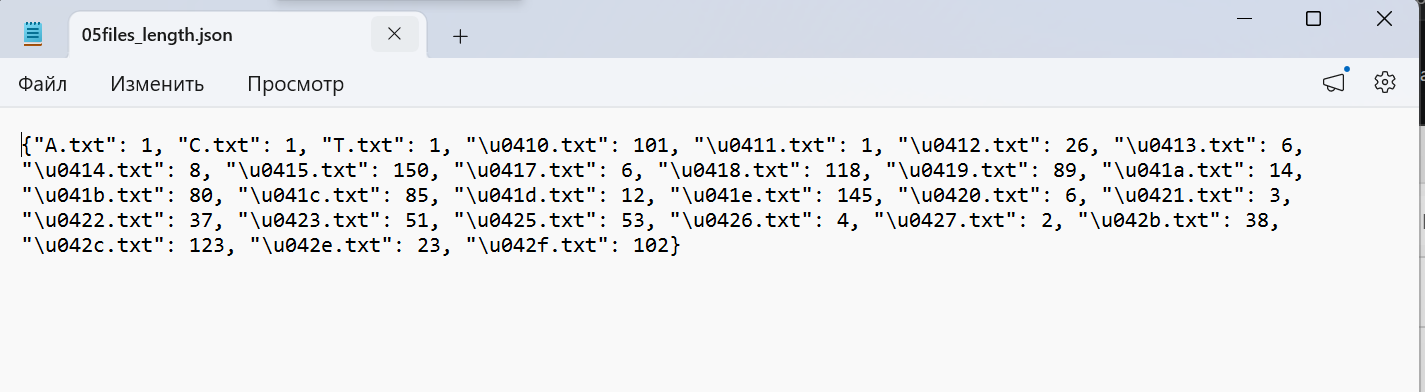

Задача 6 (*) - на креатив.

Напишите игру "Угадай столицу". Нужно собрать (можно из википедии) достаточный список стран. У вас должен получиться текстовый файл в формате

    страна\tстолица\tнаселение

При запуске программа считывает данные из этого файла и сообщает, сколько у нас всего стран. В бесконечном цикле, который останавливается, когда пользователь выбирает выйти, предлагается играть, показать список стран и выйти. При выборе "играть" запускается функция play_game(), в которой спрашивается, сколько раундов хочет сыграть человек и сколько вариантов ответов ему предлагать. Потом в цикле for игра спрашивает столицу какой-нибудь страны (страны не должны повторяться!) и выбранное количество вариантов. За правильный ответ игра начисляет (1e+8 / население страны) - таким образом будет учитываться размер страны, например, для крошечной страны баллы будут больше. Можете подумать, как улучшить начисление баллов.

Вам пригодятся функции из модуля random:

    from random import choice, sample, shuffle

In [ ]:
# создадим этот список
# text = 'Австралия\tКанберра\t27012300\nАвстрия\tВена\t8979894\nАзербайджан\tБаку\t10204247\nАлбания\tТирана\t2793592\nАлжир\tАлжир\t45400000\nАргентина\tБуэнос-Айрес\t47327407\nАрмения\tЕреван\t3039700\nАфганистан\tКабул\t43373950\nБеларусь\tМинск\t9155978\nБельгия\tБрюссель\t11584008\nБолгария\tСофия\t6847402\nБразилия\tБразилиа\t220051512\nВеликобритания\tЛондон\t66971411\nВенгрия\tБудапешт\t9689010\nВьетнам\tХаной\t100195275\nГвинея\tКонакри\t12771000\nГермания\tБерлин\t84358845\nГреция\tАфины\t10482487\nГрузия\tТбилиси\t3694600\nДания\tКопенгаген\t5962689\nЕгипет\tКаир\t106221670\nЗимбабве\tХараре\t14862927\nИндия\tНью-Дели\t1410000000\nИндонезия\tДжакарта\t282477584\nИордания\tАмман\t11484805\nИрак\tБагдад\t46400000\nИран\tТегеран\t81000000\nИрландия\tДублин\t5123536\nИсландия\tРейкьявик\t368590\nИспания\tМадрид\t48592909\nИталия\tРим\t58782813\nКазахстан\tАстана\t20286084\nКамбоджа\tПномпень\t17638801\nКанада\tОттава\t40000000\nКатар\tДоха\t2846118\nКения\tНайроби\t52428290\nКитай\tПекин\t1411750000\nКолумбия\tБогото\t49336454\nКорея\tСеул\t51751065\nКоста-Рика\tСан-Хосе\t5097988\nКуба\tГавана\t11061886\nКыргызстан\tБишкек\t7231000\nЛатвия\tРига\t1871882\nЛиван\tБейрут\t5364482\nЛитва\tВильнюс\t2895058\nЛихтенштейн\tВадуц\t38900\nЛюксембург\tЛюксембург\t672050\nМалайзия\tКуала-Лумпур\t32763726\nМальта\tВаллетта\t553214\nМарокко\tРабат\t37112080\nМексика\tМехико\t129151256\nМолдова\tКишинёв\t2603813\nМонако\tМонако\t38100\nМонголия\tУлан-Батор\t3504741\nМьянма\tНейпьидо\t52885223\nНамибия\tВиндхук\t2533794\nНепал\tКатманду\t29164578\nНигер\tНиамей\t23470530\nНигерия\tАбуджа\t229150000\nНидерланды\tАмстердам\t17947600\nНовая Зенландия\tВеллингтон\t5157270\nНорвегия\tОсло\t5594340\nОАЭ\tАбу-Даби\t9594834\nОман\tМаскат\t7199694\nПакистан\tИсламабад\t241499431\nПанама\tПанама\t4252620\nПарагвай\tАнунсьон\t6811297\nПеру\tЛима\t32162184\nПольша\tВаршава\t37636508\nПортугалия\tЛиссабон\t10467366\nРоссия\tМосква\t146150789\nРуанда\tКигали\t14256567\nРумыния\tБухарест\t19038098\nСаудовская Аравия\tЭр-Рияд\t34218169\nСеверная Македония\tСкопье\t2073702\nСенегал\tДакар\t18103345\nСербия\tБелград\t6605168\nСингапур\tСингапур\t6028459\nСирия\tДамаск\t16139840\nСловакия\tБратислава\t5466965\nСловения\tЛюбляна\t2089228\nСША\tВашингтон\t331108434\nСомали\tМогадишо\t15443000\nСуринам\tПарамарибо\t575990\nТаджикистан\tДушанбе\t10000000\nТаиланд\tБангкок\t66171493\nТунис\tТунис\t11708370\nТуркменистан\tАшхабад\t643000000\nТурция\tСтамбул\t85372377\nУзбекистан\tТашкент\t37535605\nУругвай\tМонтевидео\t3499451\nФилиппины\tМанила\t114163719\nФинляндия\tХельсинки\t5608218\nФранция\tПариж\t68521974\nХорватия\tЗагреб\t4188853\nЧерногория\tПодгорица\t633158\nЧехия\tПрага\t10900555\nЧили\tСантьяго\t18664652\nШвейцария\tБерн\t8962300\nШвеция\tСтокгольм\t10587710\nЭквадор\tКито\t18267203\nЭстония\tТаллин\t1374687\nЭфиопия\tАддис-Абеба\t116462712\nЮАР\tКейптаун\t60604992\nЯмайка\tКингстон\t2930050\nЯпония\tТокио\t124342000'
# with open('sem07/06countries.txt', 'w', encoding='utf8') as base:
#     base.write(text)

In [9]:
from random import choice, sample, shuffle
import math

def play_game(countries, cities):
    rounds = int(input('Введите количество раундов, сколько хотите играть'))
    while rounds > len(countries):
        print('Слишком большое число')
        rounds = int(input('Введите количество раундов, сколько хотите играть'))
    am_answers = int(input('Введите количество вариантов ответов'))
    while am_answers > len(countries):
        print('Слишком большое число')
        am_answers = int(input('Введите количество вариантов ответов'))
    game_countries = countries[:]
    result = 0
    for i in range(rounds):
        print('Раунд', i + 1)
        game_country = choice(game_countries)
        game_countries.remove(game_country)
        print('Какая столица страны', game_country, '\nВарианты ответов:')
        country_ind = countries.index(game_country)
        answer = all_countries[country_ind][1]
        game_cities = sample(cities, am_answers - 1)
        game_cities.append(answer)
        shuffle(game_cities)
        print(*game_cities, sep=' - ')
        user_city = input('Ваш ответ: ')
        country_ind = countries.index(game_country)
        if answer == user_city:
            print('Верно!')
            result += (1e+8) / int(all_countries[country_ind][2])
        else:
            print('Неверно :()')
    print(f'Игра закончена!\nВы набрали баллов: {round(result)}')
        

with open('sem07/06countries.txt', 'r', encoding='utf8') as file:
    all_countries = file.read().split('\n')
    countries = []
    cities = []
    for ind, country in enumerate(all_countries):
        all_countries[ind] = all_countries[ind].split('\t')
        countries.append(all_countries[ind][0])
        cities.append(all_countries[ind][1])
    print('Всего стран в игре:', len(countries))
        

while True:
    print('Выберите действие:\n\t0 - Выйти из игры\n\t1 - Показать список стран\n\t2 - Играть')
    user = int(input())
    if user == 0:
        break
    elif user == 1:
        print(countries)
    elif user == 2:
        play_game(countries, cities)
    else:
        print('Такой команды нет')

Всего стран в игре: 106
Выберите действие:
	0 - Выйти из игры
	1 - Показать список стран
	2 - Играть
['Австралия', 'Австрия', 'Азербайджан', 'Албания', 'Алжир', 'Аргентина', 'Армения', 'Афганистан', 'Беларусь', 'Бельгия', 'Болгария', 'Бразилия', 'Великобритания', 'Венгрия', 'Вьетнам', 'Гвинея', 'Германия', 'Греция', 'Грузия', 'Дания', 'Египет', 'Зимбабве', 'Индия', 'Индонезия', 'Иордания', 'Ирак', 'Иран', 'Ирландия', 'Исландия', 'Испания', 'Италия', 'Казахстан', 'Камбоджа', 'Канада', 'Катар', 'Кения', 'Китай', 'Колумбия', 'Корея', 'Коста-Рика', 'Куба', 'Кыргызстан', 'Латвия', 'Ливан', 'Литва', 'Лихтенштейн', 'Люксембург', 'Малайзия', 'Мальта', 'Марокко', 'Мексика', 'Молдова', 'Монако', 'Монголия', 'Мьянма', 'Намибия', 'Непал', 'Нигер', 'Нигерия', 'Нидерланды', 'Новая Зенландия', 'Норвегия', 'ОАЭ', 'Оман', 'Пакистан', 'Панама', 'Парагвай', 'Перу', 'Польша', 'Португалия', 'Россия', 'Руанда', 'Румыния', 'Саудовская Аравия', 'Северная Македония', 'Сенегал', 'Сербия', 'Сингапур', 'Сирия', '